# 1. Data Loading and Exploration

## Importing Libraries
pandas/numpy for data handling, matplotlib/seaborn for plots, scikit-learn for the model and metrics.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Loading the Dataset

In [6]:
df = pd.read_csv("water_consumption.csv")
display(df.head())

,USO2013,TU,DC,M,UL,f.1_ENE_09,f.1_FEB_09,f.1_MAR_09,f.1_ABR_09,f.1_MAY_09,...,f.1_MAR_15,f.1_ABR_15,f.1_MAY_15,f.1_JUN_15,f.1_JUL_15,f.1_AGO_15,f.1_SEP_15,f.1_OCT_15,f.1_NOV_15,f.1_DIC_15
0,H3,DOMESTICO MEDIO,0.5,MSDELAUNET,197.0,20.0,20.0,20.0,20.0,20.0,...,2.0,1.0,2.0,1.0,7.0,7.0,42.0,27.0,22.0,21.0
1,H3,DOMESTICO MEDIO,0.5,MSDELAUNET,307.0,NaN,30.0,30.0,30.0,30.0,...,11.0,13.0,16.0,14.0,15.0,16.0,13.0,17.0,17.0,11.0
2,H3,DOMESTICO RESIDENCIAL,0.5,MSDELAUNET,179.0,NaN,NaN,NaN,NaN,NaN,...,6.0,9.0,7.0,8.0,8.0,10.0,12.0,9.0,6.0,3.0
3,H3,DOMESTICO MEDIO,0.5,CICASA MMD-15 S,852.0,NaN,NaN,NaN,NaN,NaN,...,17.0,20.0,16.0,16.0,18.0,18.0,17.0,17.0,18.0,9.0
4,H3,DOMESTICO RESIDENCIAL,0.5,NaN,NaN,20.0,20.0,20.0,20.0,20.0,...,27.0,27.0,27.0,28.0,28.0,31.0,27.0,27.0,27.0,24.0


## Basic Inspection
Shape of the data, then column types and non-null counts.

In [7]:
print(df.shape)

(178597, 89)


In [8]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 178597 entries, 0 to 178596
Data columns (total 89 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   USO2013     178597 non-null  str    
 1   TU          178597 non-null  str    
 2   DC          178597 non-null  float64
 3   M           137526 non-null  str    
 4   UL          135511 non-null  float64
 5   f.1_ENE_09  144882 non-null  float64
 6   f.1_FEB_09  146783 non-null  float64
 7   f.1_MAR_09  147124 non-null  float64
 8   f.1_ABR_09  147558 non-null  float64
 9   f.1_MAY_09  148487 non-null  float64
 10  f.1_JUN_09  149379 non-null  float64
 11  f.1_JUL_09  149873 non-null  float64
 12  f.1_AGO_09  150201 non-null  float64
 13  f.1_SEP_09  150683 non-null  float64
 14  f.1_OCT_09  151141 non-null  float64
 15  f.1_NOV_09  151374 non-null  float64
 16  f.1_DIC_09  151712 non-null  float64
 17  f.1_ENE_10  151931 non-null  float64
 18  f.1_FEB_10  152735 non-null  float64
 19  f.1_MAR_10  1

## Finding the Monthly Columns
Columns starting with `f.1_` hold the monthly water consumption values.

In [9]:
monthly_cols = [col for col in df.columns if col.startswith("f.1_")]

print("Number of monthly columns:", len(monthly_cols))
print(monthly_cols)

Number of monthly columns: 84
['f.1_ENE_09', 'f.1_FEB_09', 'f.1_MAR_09', 'f.1_ABR_09', 'f.1_MAY_09', 'f.1_JUN_09', 'f.1_JUL_09', 'f.1_AGO_09', 'f.1_SEP_09', 'f.1_OCT_09', 'f.1_NOV_09', 'f.1_DIC_09', 'f.1_ENE_10', 'f.1_FEB_10', 'f.1_MAR_10', 'f.1_ABR_10', 'f.1_MAY_10', 'f.1_JUN_10', 'f.1_JUL_10', 'f.1_AGO_10', 'f.1_SEP_10', 'f.1_OCT_10', 'f.1_NOV_10', 'f.1_DIC_10', 'f.1_ENE_11', 'f.1_FEB_11', 'f.1_MAR_11', 'f.1_ABR_11', 'f.1_MAY_11', 'f.1_JUN_11', 'f.1_JUL_11', 'f.1_AGO_11', 'f.1_SEP_11', 'f.1_OCT_11', 'f.1_NOV_11', 'f.1_DIC_11', 'f.1_ENE_12', 'f.1_FEB_12', 'f.1_MAR_12', 'f.1_ABR_12', 'f.1_MAY_12', 'f.1_JUN_12', 'f.1_JUL_12', 'f.1_AGO_12', 'f.1_SEP_12', 'f.1_OCT_12', 'f.1_NOV_12', 'f.1_DIC_12', 'f.1_ENE_13', 'f.1_FEB_13', 'f.1_MAR_13', 'f.1_ABR_13', 'f.1_MAY_13', 'f.1_JUN_13', 'f.1_JUL_13', 'f.1_AGO_13', 'f.1_SEP_13', 'f.1_OCT_13', 'f.1_NOV_13', 'f.1_DIC_13', 'f.1_ENE_14', 'f.1_FEB_14', 'f.1_MAR_14', 'f.1_ABR_14', 'f.1_MAY_14', 'f.1_JUN_14', 'f.1_JUL_14', 'f.1_AGO_14', 'f.1_SEP_14', 'f.

## Handling Missing Values
Counts missing values in the monthly columns and drops any rows that have them.

In [10]:
print(df[monthly_cols].isnull().sum().sum())
df_clean = df.copy()
df_clean = df_clean.dropna(subset=monthly_cols)
print(df_clean.shape)

1309971
(141205, 89)


## Average Monthly Trend
Plots the average consumption for each month (2009–2015).

f.1_ENE_09     65.652781
f.1_FEB_09     48.728721
f.1_MAR_09     38.396537
f.1_ABR_09     42.430856
f.1_MAY_09     47.362664
                 ...    
f.1_AGO_15    121.997309
f.1_SEP_15    134.207330
f.1_OCT_15     73.324025
f.1_NOV_15    103.458921
f.1_DIC_15     95.650968
Length: 84, dtype: float64


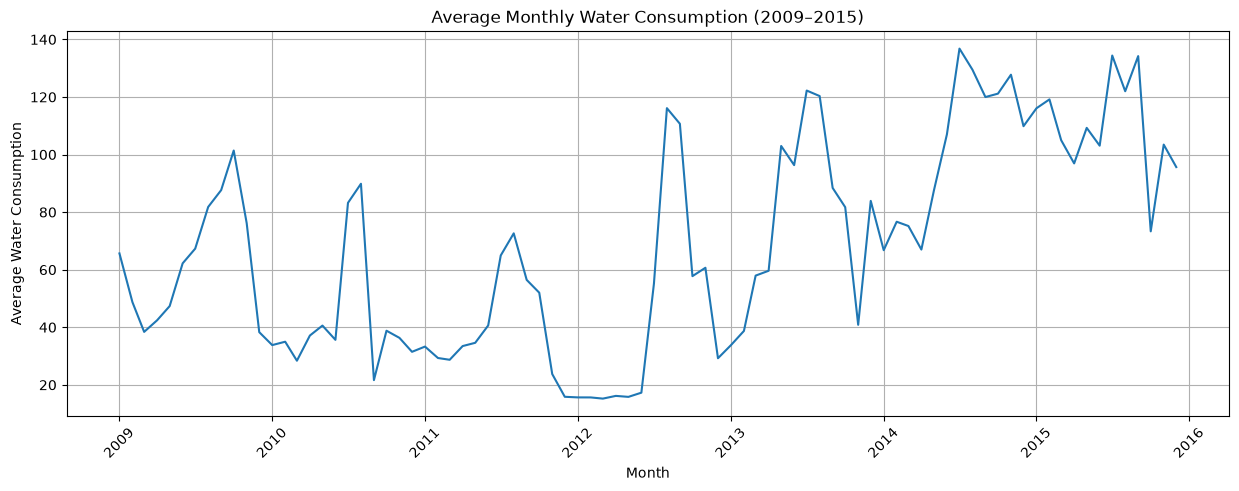

In [11]:
monthly_avg = df_clean[monthly_cols].mean()

print(monthly_avg)
months = pd.date_range(start="2009-01-01", periods=84, freq="MS")

plt.figure(figsize=(15, 5))
plt.plot(months, monthly_avg.values)
plt.xlabel("Month")
plt.ylabel("Average Water Consumption")
plt.title("Average Monthly Water Consumption (2009–2015)")
plt.xticks(rotation=45)
plt.grid()
plt.show()

In [12]:
print(df_clean.shape)
print(df_clean[monthly_cols].isnull().sum().sum())
display(df_clean[monthly_cols].describe())

(141205, 89)
0


,f.1_ENE_09,f.1_FEB_09,f.1_MAR_09,f.1_ABR_09,f.1_MAY_09,f.1_JUN_09,f.1_JUL_09,f.1_AGO_09,f.1_SEP_09,f.1_OCT_09,...,f.1_MAR_15,f.1_ABR_15,f.1_MAY_15,f.1_JUN_15,f.1_JUL_15,f.1_AGO_15,f.1_SEP_15,f.1_OCT_15,f.1_NOV_15,f.1_DIC_15
count,141205.000000,141205.000000,141205.000000,141205.000000,141205.000000,141205.000000,141205.000000,141205.000000,141205.000000,141205.000000,...,141205.000000,141205.000000,141205.000000,141205.000000,141205.000000,141205.000000,141205.000000,141205.000000,141205.000000,141205.000000
mean,65.652781,48.728721,38.396537,42.430856,47.362664,62.208881,67.316936,81.802472,87.641606,101.399632,...,104.989363,96.926568,109.274289,103.086576,134.405786,121.997309,134.207330,73.324025,103.458921,95.650968
std,354.240140,233.855858,176.717645,199.714877,240.325118,344.760093,376.262471,475.405624,523.531938,622.544714,...,670.835136,593.019233,692.794664,637.528864,859.551706,771.091240,861.345458,414.931718,638.868102,596.645358
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,12.000000,11.000000,11.000000,12.000000,13.000000,12.000000,13.000000,13.000000,12.000000,12.000000,...,9.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,8.000000
50%,19.000000,18.000000,18.000000,19.000000,20.000000,19.000000,19.000000,19.000000,19.000000,19.000000,...,15.000000,18.000000,16.000000,16.000000,17.000000,17.000000,17.000000,17.000000,17.000000,15.000000
75%,23.000000,23.000000,22.000000,23.000000,24.000000,23.000000,24.000000,25.000000,23.000000,23.000000,...,22.000000,24.000000,22.000000,23.000000,24.000000,23.000000,23.000000,23.000000,23.000000,22.000000
max,24692.000000,24130.000000,24130.000000,26236.000000,42420.000000,44505.000000,48029.000000,49922.000000,48978.000000,49915.000000,...,55162.000000,50955.000000,49325.000000,31328.000000,24809.000000,19885.000000,6476.000000,5185.000000,34863.000000,34597.000000


In [13]:
X = df_clean[['f.1_MAY_09', 'f.1_JUN_09', 'f.1_JUL_09']]

y = df_clean['f.1_AGO_09']

print(X.shape)
print(y.shape)

(141205, 3)
(141205,)


# 2. Model Building

## Selecting Features and Target
Uses May, June and July 2009 consumption (`X`) to predict August 2009 (`y`).

## Creating the Model
A simple linear regression model.

In [14]:
model = LinearRegression()

## Train-Test Split
80% of the data for training, 20% for testing.

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(X_train.shape)
print(X_test.shape)

(112964, 3)
(28241, 3)


## Training the Model
Fits the model on the training data and prints the learned coefficients and intercept.

In [16]:
model.fit(X_train, y_train)
print("Coefficients:", model.coef_)
print("Intercept:", model.intercept_)

Coefficients: [-0.84430967  0.65023864  1.19276068]
Intercept: 1.0366298330416726


# 3.Predicting  the AI Model

In [17]:
y_pred = model.predict(X_test)

In [18]:
results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})

display(results.head())

,Actual,Predicted
96887,11.0,28.264698
163807,20.0,21.010423
12812,21.0,18.711256
55183,25.0,23.047493
135816,20.0,21.010423


## Actual vs Predicted Scatter Plot
Points close to a diagonal line mean accurate predictions.

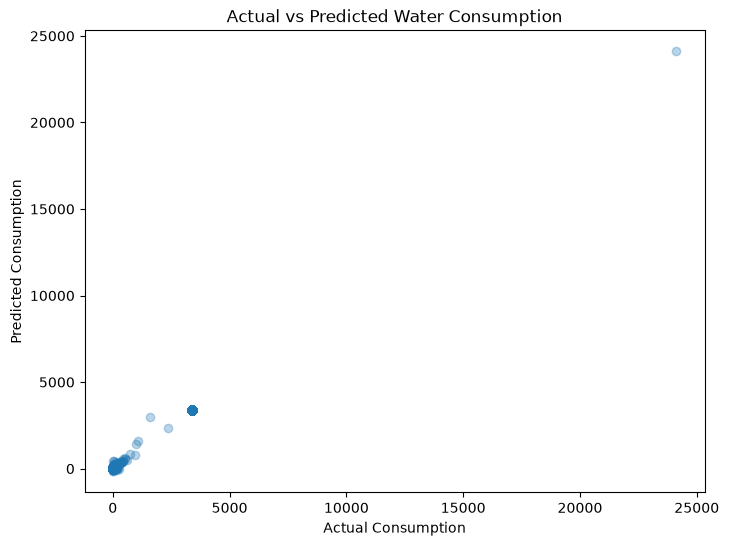

In [19]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.3)
plt.xlabel("Actual Consumption")
plt.ylabel("Predicted Consumption")
plt.title("Actual vs Predicted Water Consumption")
plt.show()

# 4.Error Analysis

## Evaluation Metrics
MAE, MSE, RMSE and R² score on the test set.

In [20]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae))
print("MSE:", round(mse))
print("RMSE:", round(rmse))
print("R2 Score:", round(r2))

MAE: 5
MSE: 214
RMSE: 15
R2 Score: 1


## Prediction Comparison (First 100 Test Samples)

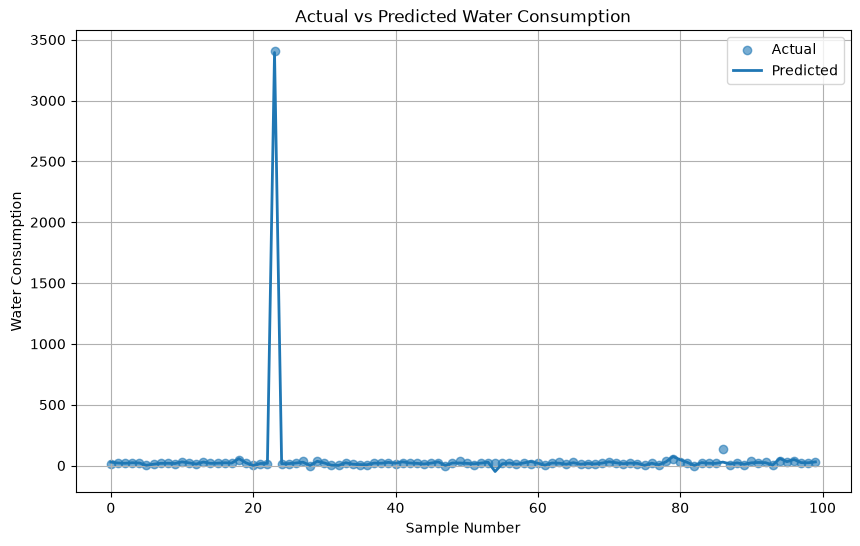

In [21]:
plt.figure(figsize=(10, 6))

plt.scatter(range(100), y_test.iloc[:100], label="Actual", alpha=0.6)
plt.plot(range(100), y_pred[:100], label="Predicted", linewidth=2)

plt.xlabel("Sample Number")
plt.ylabel("Water Consumption")
plt.title("Actual vs Predicted Water Consumption")
plt.legend()
plt.grid()
plt.show()